Objetivo:
Quantificar, em imagens de microscopia, o número de células positivas para a transformação pelo plasmídeo de expressão da proteína de P. vivax;

In [1]:
import os #organizador de pasta
import numpy as np #estruturação dos dados
import matplotlib.pyplot as plt #plot gráfico
import seaborn as sns #plot gráfico
from PIL import Image #visualização de img
import pandas as pd #estruturação dos dados
from util import meus_uteis, timeProcess
import joblib #convertendo imagens em valores numéricos .gz
from sklearn.utils import shuffle # embaralhar listas e arrays de forma consistente
from util import meus_uteis, timeProcess, mask_corr_graphic, printLis

Foram criadas 3 pastas a partir das imagens originais. Uma das pastas recebeu as imagens sem marcador, outra pasta recebeu as imagens marcadas sem rótulo e a terceira pasta recebeu as imagens marcadas com os rótulos. Nesse notebook, estamos trabalhando com 39 (iniciais) imagens não marcadas com os rótulos.

In [2]:
# Link antigoa da pasta original
# novas_imagens = '/content/drive/MyDrive/teste/imagens_julia_quantificacao/contraste de fase' #diretório

novas_imagens = "./data/imagens de contraste de fase (CHO745)/"
img_key = 0 #Chave da primeira imagem

lista_novas_img = [i for i in os.listdir(novas_imagens) if i.endswith('.tif')] #listando as figuras salvas no diretório
len(lista_novas_img) #quantidade de imagens

39

In [3]:
lista_novas_img[:3]

['test_Experiment_CHO_745_EFGP_v04_ch00_rot648.tif',
 'test_Experiment_CHO_745_EFGP_v11_ch00_rot712.tif',
 'test_Experiment_CHO_745_EFGP_v19_ch00_rot282.tif']

In [4]:
# 1. Criar uma cópia e embaralhar aleatoriamente
lista = lista_novas_img.copy()
lista_embaralhada = shuffle(lista, random_state=42)

# 2. Definir os tamanhos exatos das amostras
tam_70 = 27
tam_20 = 8

# 3. Fatiar a lista embaralhada nos 3 grupos
lista_70 = lista_embaralhada[:tam_70]
lista_20 = lista_embaralhada[tam_70 : tam_70 + tam_20]
lista_10 = lista_embaralhada[tam_70 + tam_20 :]

# Verificação do tamanho de cada lista
print(f"Lista 70% ({len(lista_70)} itens): {lista_70[:2]}")
print(f"Lista 20% ({len(lista_20)} itens): {lista_20[:2]}")
print(f"Lista 10% ({len(lista_10)} itens): {lista_10[:2]}")

Lista 70% (27 itens): ['train_Experiment_CHO_745_EFGP_v38_ch00_rot478.tif', 'valid_Experiment_CHO_745_EFGP_v15_ch00_rot218.tif']
Lista 20% (8 itens): ['test_Experiment_CHO_745_EFGP_v21_ch00_rot198.tif', 'train_Experiment_CHO_745_EFGP_v39_ch00_rot450.tif']
Lista 10% (4 itens): ['test_Experiment_CHO_745_EFGP_v36_ch00_rot435.tif', 'train_Experiment_CHO_745_EFGP_v09_ch00_rot520.tif']


In [5]:
[os.rename(novas_imagens+i, novas_imagens+"train_"+i) for i in lista_70]
[os.rename(novas_imagens+i, novas_imagens+"test_"+i) for i in lista_20]
[os.rename(novas_imagens+i, novas_imagens+"valid_"+i) for i in lista_10]

[None, None, None, None]

In [6]:
lista_novas_img = [i for i in os.listdir(novas_imagens) if i.endswith('.tif')] #listando as figuras salvas no diretório
len(lista_novas_img) #quantidade de imagens

39

In [7]:
lista_novas_img[:3]

['test_test_Experiment_CHO_745_EFGP_v21_ch00_rot198.tif',
 'test_train_Experiment_CHO_745_EFGP_v03_ch00_rot571.tif',
 'test_train_Experiment_CHO_745_EFGP_v14_ch00_rot123.tif']

Visualização das imagens (x): Melhor resolução 300x300

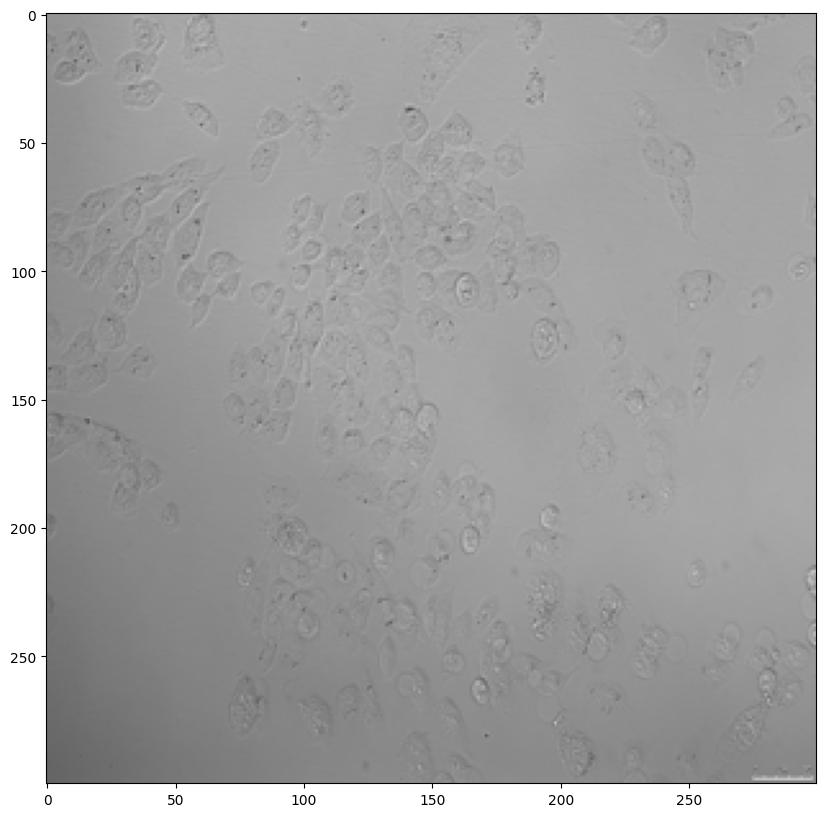

In [8]:
#testando as imagens
resize_img = (300,300) #tamanho da imagem
image_test = novas_imagens +'/'+ lista_novas_img[img_key] #chamando a primeira imagem
img = Image.open(image_test) #abrinado a primeira imagem
img = img.resize(resize_img) #formatando o tamanho

#visualização da imagem
plt.figure(figsize=(10,10))
plt.imshow(img)
plt.show()

Label = y (39)
Os rótulos devem acompanhar o numero de imagens, ou seja, 40 imagens, 40 rótulos que correspondam o numero de células marcadas nas imagens.

#1. Original orientation of the image.

In [9]:
y_rotulo_imagem = [n.split('rot')[1] for n in lista_novas_img] #cortando informações da imagem
y_rotulo_imagem = [(n.split('.tif')[0]) for n in y_rotulo_imagem]
y_rotulo_imagem = y_rotulo_imagem
print(len(y_rotulo_imagem)) #verificando o numero de rótulos corresponde o numero de imagens
print(y_rotulo_imagem[:3])

39
['198', '571', '123']


Formatting all images that are saved in the directory into an array - 39 images

In [10]:
lista_file_names = []
lista_imagens_camp_claro = [] #lista vazia onde vai ser armazenado os dados
for file in lista_novas_img[:]:  #laço pra salvar todas as imagens
    image_test = novas_imagens +'/'+ file #qual caminho
    img = Image.open(image_test) #abrir a imagem
    img = img.resize(resize_img) #formatando em 300x300
    img = np.asarray(img)[:,:,:3] #formatando em array
    lista_imagens_camp_claro.append(img)  #adicionando cada imagem
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape #verificando quantas imagens foram salvas em qual tamnho e camadas

(39, 300, 300, 3)

In [11]:
lista_imagens_camp_claro[0].shape

(300, 300, 3)

# 2. Saving inverted images from left to right

label (78 - doubled) - dobrando o numero de rótulos

In [12]:
#dobrando o numero de rótulos - mesmo que a imagem esteja invertida, ela possui mesmo rótulo
y_rotulo_soma = y_rotulo_imagem + y_rotulo_imagem
len(y_rotulo_soma)

78

In [13]:
y_rotulo_soma[:3]

['198', '571', '123']

In [14]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape

(78, 300, 300, 3)

# 3. Saving inverted images from bottom to top

y = label (117 - doubled)

In [15]:
#dobrando o numero de rótulos - mesmo que a imagem esteja invertida, ela possui mesmo rótulo
y_rotulo_soma += y_rotulo_imagem
len(y_rotulo_soma)

117

In [16]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape

(117, 300, 300, 3)

# 4. Saving the images flipped upside down.

label (156 - doubled) - dobrando o numero de rótulos

In [17]:
y_rotulo_soma += y_rotulo_imagem
len(y_rotulo_soma)

156

In [18]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape

(156, 300, 300, 3)

Salvando em uma lista as imagens em diferentes orientações.

In [19]:
data = timeProcess()[1]
joblib.dump(np.asarray(lista_imagens_camp_claro), f'{novas_imagens}lista_img_100_resized_regre_cho745_{data}.gz')

['./data/imagens de contraste de fase (CHO745)/lista_img_100_resized_regre_cho745_2026-10-16.gz']

In [20]:
joblib.dump(np.asarray(y_rotulo_soma), f'{novas_imagens}lista_rotulo_100_resized_regre_cho745_{data}.gz')

['./data/imagens de contraste de fase (CHO745)/lista_rotulo_100_resized_regre_cho745_2026-10-16.gz']

#1. Cropping 75% of the image/enlarging the image bank

In [21]:
#formula para calcular os rótulos
from math import ceil

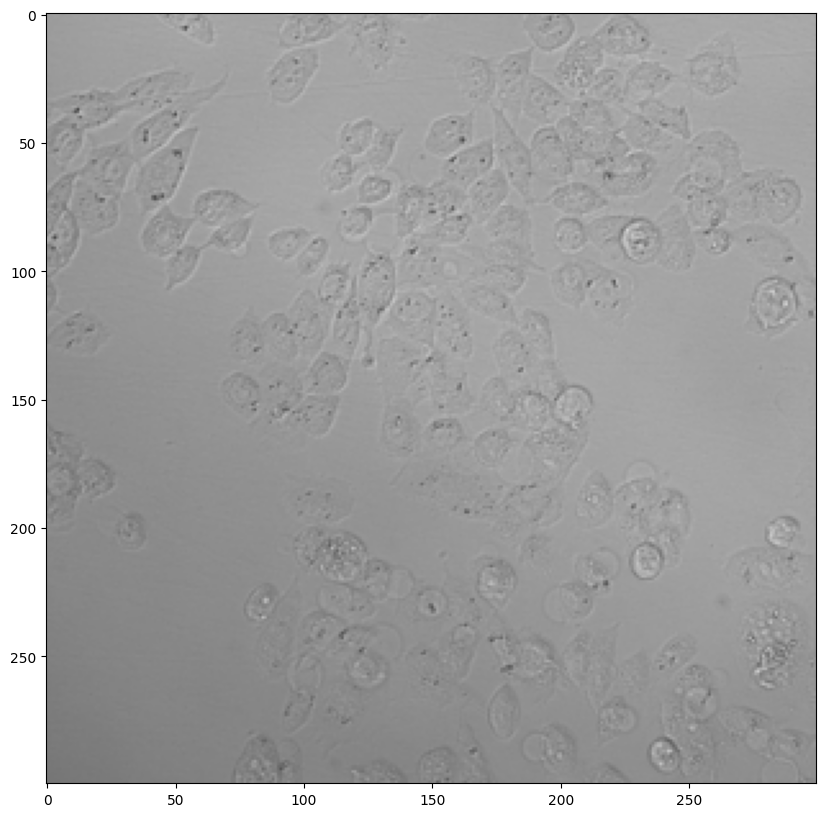

In [22]:
box = (135,135,945,945)

image_test = novas_imagens +'/'+ lista_novas_img[img_key] #chamando a primeira imagem
img = Image.open(image_test) #abrinado a primeira imagem
img = img.crop(box=box)
img = img.resize(resize_img) #formatando o tamanho

#visualização da imagem
plt.figure(figsize=(10,10))
plt.imshow(img)
plt.show()

label (39 - doubled)

In [23]:
y_rotulo_imagem = [n.split('rot')[1] for n in lista_novas_img]
y_rotulo_imagem = [int(n.split('.tif')[0]) for n in y_rotulo_imagem]
y_rotulo_imagem = [ceil(n-(n*0.25)) for n in y_rotulo_imagem]
len(y_rotulo_imagem)

39

In [24]:
lista_imagens_camp_claro = []
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file #qual caminho
    img = Image.open(image_test)
    img = img.crop(box=box)
    img = img.resize(resize_img)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape

(39, 300, 300, 3)

#2. crop images 75% resized and rotating from left to right

label (78 - doubled) - dobrando o numero de rótulos


In [25]:
y_rotulo_soma = y_rotulo_imagem + y_rotulo_imagem
len(y_rotulo_soma)

78

In [26]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.crop(box=box)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape

(78, 300, 300, 3)

#3. crop image 75% resized and flipping from bottom to top

label (117 - doubled) - dobrando o numero de rótulos

In [27]:
y_rotulo_soma += y_rotulo_imagem
len(y_rotulo_soma)

117

In [28]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.crop(box=box)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape

(117, 300, 300, 3)

# 4. Saving crop 75% resized and flip top bottom image

label (156 - doubled) - dobrando o numero de rótulos

In [29]:
y_rotulo_soma += y_rotulo_imagem
len(y_rotulo_soma)

156

In [30]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.crop(box=box)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape

(156, 300, 300, 3)

In [31]:
joblib.dump(np.asarray(lista_imagens_camp_claro), f'{novas_imagens}lista_img_75_resized_regre_cho745_{data}.gz')

['./data/imagens de contraste de fase (CHO745)/lista_img_75_resized_regre_cho745_2026-10-16.gz']

In [32]:
joblib.dump(np.asarray(y_rotulo_soma), f'{novas_imagens}lista_rotulo_75_resized_regre_cho745_{data}.gz')

['./data/imagens de contraste de fase (CHO745)/lista_rotulo_75_resized_regre_cho745_2026-10-16.gz']

#1. Crop 50% of the image

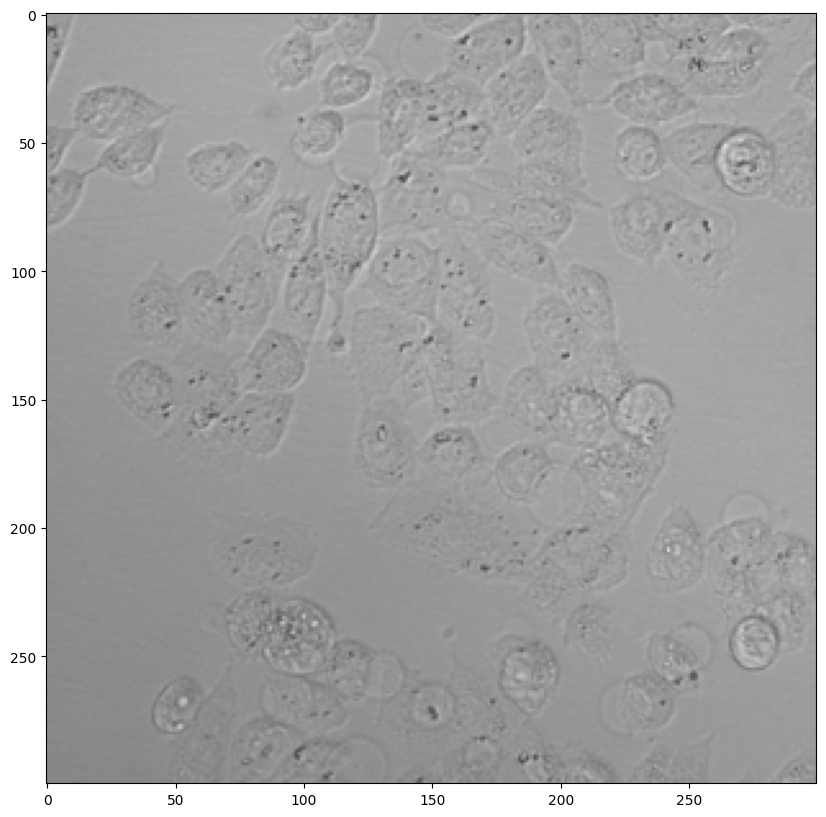

In [33]:
box = (270,270,810,810)

image_test = novas_imagens +'/'+ lista_novas_img[img_key] #chamando a primeira imagem
img = Image.open(image_test) #abrinado a primeira imagem
img = img.crop(box=box)
img = img.resize(resize_img) #formatando o tamanho

#visualização da imagem
plt.figure(figsize=(10,10))
plt.imshow(img)
plt.show()

label (39 - doubled)

In [34]:
y_rotulo_imagem = [n.split('rot')[1] for n in lista_novas_img]
y_rotulo_imagem = [int(n.split('.tif')[0]) for n in y_rotulo_imagem]
y_rotulo_imagem = [ceil(n/2) for n in y_rotulo_imagem]
len(y_rotulo_imagem)

39

In [35]:
lista_imagens_camp_claro = []
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file #qual caminho
    img = Image.open(image_test)
    img = img.crop(box=box)
    img = img.resize(resize_img)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape

(39, 300, 300, 3)

#2. Saving crop 50% resized and turn image left right

label (78 - doubled)

In [36]:
y_rotulo_soma = y_rotulo_imagem + y_rotulo_imagem
len(y_rotulo_soma)

78

In [37]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.crop(box=box)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape

(78, 300, 300, 3)

#3. Saving 50% resized crop and flip top bottom image

label (117 - doubled)


In [38]:
y_rotulo_soma += y_rotulo_imagem
len(y_rotulo_soma)

117

In [39]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.crop(box=box)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape

(117, 300, 300, 3)

#4. Saving crop 50% resized and flip top bottom image

In [40]:
y_rotulo_soma += y_rotulo_imagem
len(y_rotulo_soma)

156

In [41]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.crop(box=box)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape

(156, 300, 300, 3)

In [42]:
joblib.dump(np.asarray(lista_imagens_camp_claro), f'{novas_imagens}lista_img_50_resized_regre_cho745_{data}.gz')

['./data/imagens de contraste de fase (CHO745)/lista_img_50_resized_regre_cho745_2026-10-16.gz']

In [43]:
joblib.dump(np.asarray(y_rotulo_soma), f'{novas_imagens}lista_rotulo_50_resized_regre_cho745_{data}.gz')

['./data/imagens de contraste de fase (CHO745)/lista_rotulo_50_resized_regre_cho745_2026-10-16.gz']

#1. Crop 25% of the image

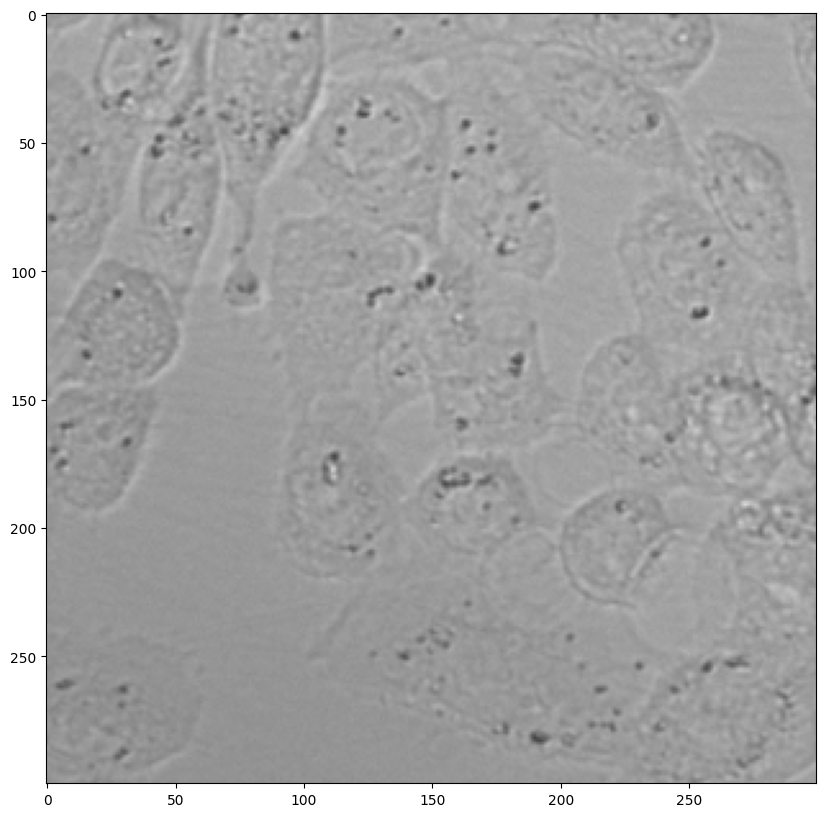

In [44]:
box = (405,405,675,675)

image_test = novas_imagens +'/'+ lista_novas_img[img_key] #chamando a primeira imagem
img = Image.open(image_test) #abrinado a primeira imagem
img = img.crop(box=box)
img = img.resize(resize_img) #formatando o tamanho

#visualização da imagem
plt.figure(figsize=(10,10))
plt.imshow(img)
plt.show()

label (39 - doubled)

In [45]:
y_rotulo_imagem = [n.split('rot')[1] for n in lista_novas_img]
y_rotulo_imagem = [int(n.split('.tif')[0]) for n in y_rotulo_imagem]
y_rotulo_imagem = [ceil(n-(n*0.75)) for n in y_rotulo_imagem]
len(y_rotulo_imagem)

39

In [46]:
lista_imagens_camp_claro = []
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file #qual caminho
    img = Image.open(image_test)
    img = img.crop(box=box)
    img = img.resize(resize_img)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape

(39, 300, 300, 3)

#2. Saving crop 25% resized and turn image left right

label (78 - doubled)

In [47]:
y_rotulo_soma = y_rotulo_imagem + y_rotulo_imagem
len(y_rotulo_soma)

78

In [48]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.crop(box=box)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape

(78, 300, 300, 3)

# 3. Saving crop 25% resized and flip top bottom image

label (117 - doubled)

In [49]:
y_rotulo_soma += y_rotulo_imagem
len(y_rotulo_soma)

117

In [50]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.crop(box=box)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape

(117, 300, 300, 3)

#4. Saving crop 25% resized and flip top bottom image

label (156 - doubled)

In [51]:
y_rotulo_soma += y_rotulo_imagem
len(y_rotulo_soma)

156

In [52]:
for file in lista_novas_img:
    image_test = novas_imagens +'/'+ file
    img = Image.open(image_test)
    img = img.crop(box=box)
    img = img.resize(resize_img)
    img = img.transpose(Image.FLIP_TOP_BOTTOM)
    img = img.transpose(Image.FLIP_LEFT_RIGHT)
    img = np.asarray(img)[:,:,:3]
    lista_imagens_camp_claro.append(img)
    lista_file_names.append(file)
np.asarray(lista_imagens_camp_claro).shape

(156, 300, 300, 3)

In [53]:
joblib.dump(np.asarray(lista_imagens_camp_claro), f'{novas_imagens}lista_img_25_resized_regre_cho745_{data}.gz')

['./data/imagens de contraste de fase (CHO745)/lista_img_25_resized_regre_cho745_2026-10-16.gz']

In [54]:
joblib.dump(np.asarray(y_rotulo_soma), f'{novas_imagens}lista_rotulo_25_resized_regre_cho745_{data}.gz')

['./data/imagens de contraste de fase (CHO745)/lista_rotulo_25_resized_regre_cho745_2026-10-16.gz']

In [57]:
joblib.dump(np.asarray(y_rotulo_soma), f'{novas_imagens}lista_file_names_resized_regre_cho745_{data}.gz')

['./data/imagens de contraste de fase (CHO745)/lista_file_names_resized_regre_cho745_2026-10-16.gz']